## Current research direction — HRI adaptation

Reusable preparation: review and adapt these steps for endemic-bird HRI assessment. Any legacy forest-loss target analysis in this notebook is exploratory, not an HRI definition.

The original code and saved outputs are retained. No cells were executed during restoration. Use `docs/methodology/hri_workflow.md` for the current direction and `notebooks/hri/` for the simple lecturer-facing versions. Do not describe existing forest-loss outputs as habitat-risk classes.

Run from the project root or `notebooks/` using the project `.venv` kernel. Raw input is in `data/raw/observations/`; review tables are in `data/interim/`; source notes are in `data/metadata/`. Existing outputs are from the pre-reorganization run; rerun to refresh displayed paths.

In [3]:
from pathlib import Path
import pandas as pd

# Resolve the project from either the root or notebooks/ working directory.
PROJECT_ROOT = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "requirements-research-lock.txt").is_file()
     and (folder / "data/raw/observations/final_dataset_complete.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from the component4 project folder.")

RAW_DATA = PROJECT_ROOT / "data/raw/observations/final_dataset_complete.csv"

df = pd.read_csv(RAW_DATA)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 102929
Columns: 23


In [4]:
summary = pd.DataFrame({
    "data_type": df.dtypes,
    "missing_rows": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
})

summary

,data_type,missing_rows,missing_percent
common_name,str,0,0.00
scientific_name,str,0,0.00
latitude,float64,0,0.00
longitude,float64,0,0.00
observation_date,str,0,0.00
year,int64,0,0.00
month,int64,0,0.00
observation_count,str,0,0.00
duration_minutes,float64,11401,11.08
effort_distance_km,float64,37057,36.00


In [5]:
duplicate_count = df.duplicated().sum()

print("Exact duplicate rows:", duplicate_count)
print("Percentage:", round(duplicate_count / len(df) * 100, 2), "%")

Exact duplicate rows: 18411
Percentage: 17.89 %


In [6]:
# Show all occurrences of repeated rows, including the first occurrence.
duplicate_rows = df[df.duplicated(keep=False)]

duplicate_rows.sort_values(
    ["scientific_name", "observation_date", "latitude", "longitude"]
).head(10)

,common_name,scientific_name,latitude,longitude,observation_date,year,month,observation_count,duration_minutes,effort_distance_km,...,temperature_min,temperature_mean,precipitation_sum,rain_sum,windspeed_max,windgusts_max,elevation,treecover2000,forest_loss,forest_loss_year
925,Ashy-headed Laughingthrush,Argya cinereifrons,6.40896,80.445328,2010-10-31,2010,10,X,NaN,NaN,...,25.0,26.3,15.6,15.6,21.2,42.8,15.0,97,0,0
926,Ashy-headed Laughingthrush,Argya cinereifrons,6.40896,80.445328,2010-10-31,2010,10,X,NaN,NaN,...,25.0,26.3,15.6,15.6,21.2,42.8,15.0,97,0,0
1468,Ashy-headed Laughingthrush,Argya cinereifrons,6.40896,80.445328,2011-01-02,2011,1,1,240.0,5.0,...,24.2,25.9,10.8,10.8,7.5,20.9,15.0,97,0,0
1472,Ashy-headed Laughingthrush,Argya cinereifrons,6.40896,80.445328,2011-01-02,2011,1,1,240.0,5.0,...,24.2,25.9,10.8,10.8,7.5,20.9,15.0,97,0,0
1471,Ashy-headed Laughingthrush,Argya cinereifrons,6.40896,80.445328,2011-01-24,2011,1,X,180.0,4.0,...,22.4,26.7,0.0,0.0,8.3,23.8,15.0,97,0,0
1475,Ashy-headed Laughingthrush,Argya cinereifrons,6.40896,80.445328,2011-01-24,2011,1,X,180.0,4.0,...,22.4,26.7,0.0,0.0,8.3,23.8,15.0,97,0,0
1469,Ashy-headed Laughingthrush,Argya cinereifrons,6.40896,80.445328,2011-01-25,2011,1,20,480.0,5.0,...,23.4,26.6,0.2,0.2,12.9,31.7,15.0,97,0,0
1473,Ashy-headed Laughingthrush,Argya cinereifrons,6.40896,80.445328,2011-01-25,2011,1,20,480.0,5.0,...,23.4,26.6,0.2,0.2,12.9,31.7,15.0,97,0,0
1466,Ashy-headed Laughingthrush,Argya cinereifrons,6.40896,80.445328,2011-01-26,2011,1,X,480.0,5.0,...,24.3,26.3,1.2,1.2,24.2,50.0,15.0,97,0,0
1474,Ashy-headed Laughingthrush,Argya cinereifrons,6.40896,80.445328,2011-01-26,2011,1,X,480.0,5.0,...,24.3,26.3,1.2,1.2,24.2,50.0,15.0,97,0,0


In [7]:
# Convert dates for inspection without changing the original column.
dates = pd.to_datetime(
    df["observation_date"],
    format="%Y-%m-%d",
    errors="coerce"
)

print("Invalid or missing dates:", dates.isna().sum())
print("Earliest observation:", dates.min())
print("Latest observation:", dates.max())

Invalid or missing dates: 0
Earliest observation: 2010-01-01 00:00:00
Latest observation: 2023-06-17 00:00:00


observation_date
2010     1246
2011     1565
2012     1541
2013     1709
2014     2602
2015     3732
2016     4526
2017     5738
2018     7302
2019     9016
2020    13408
2021    16388
2022    21187
2023    12969
Name: count, dtype: int64


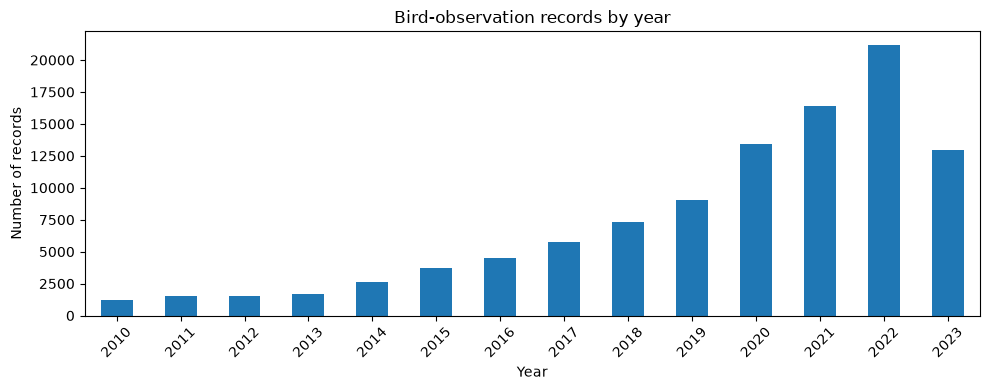

In [8]:
import matplotlib.pyplot as plt

# Count records for each year using the parsed observation dates.
records_per_year = dates.dt.year.value_counts().sort_index()

print(records_per_year)

records_per_year.plot(kind="bar", figsize=(10, 4))

plt.title("Bird-observation records by year")
plt.xlabel("Year")
plt.ylabel("Number of records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Number of species: 25


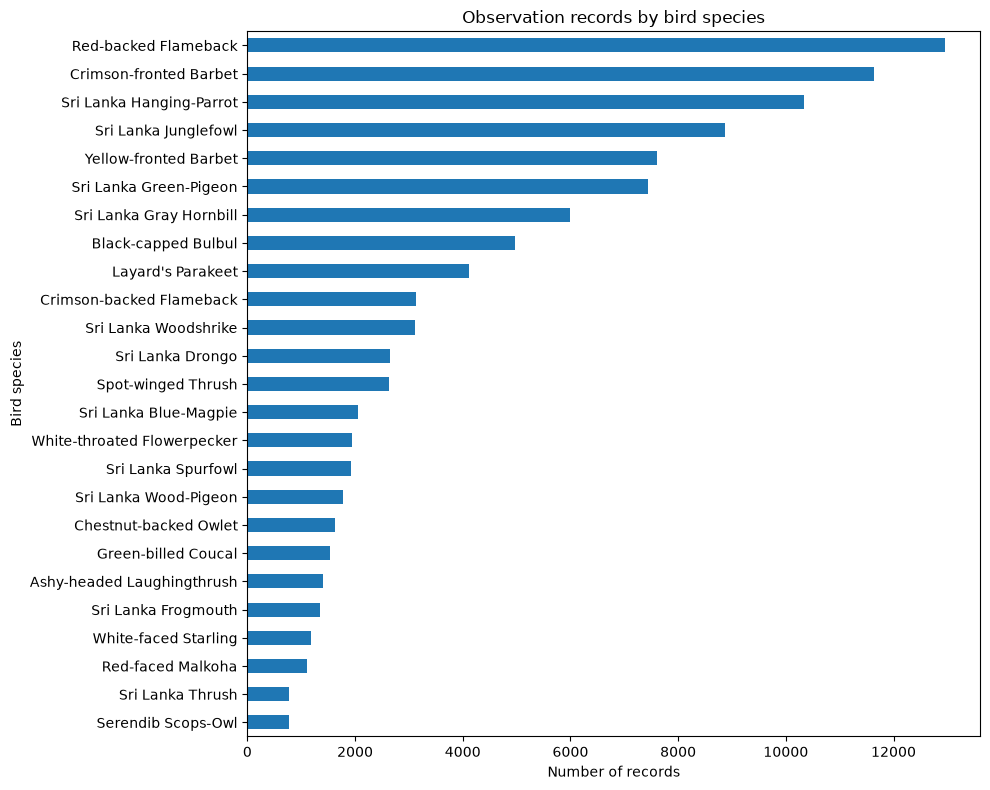

In [9]:
species_counts = df["common_name"].value_counts()

print("Number of species:", df["scientific_name"].nunique())

species_counts.sort_values().plot(
    kind="barh",
    figsize=(10, 8)
)

plt.title("Observation records by bird species")
plt.xlabel("Number of records")
plt.ylabel("Bird species")
plt.tight_layout()
plt.show()

In [10]:
# Check missing coordinates and valid global ranges.
valid_coordinates = (
    df["latitude"].between(-90, 90)
    & df["longitude"].between(-180, 180)
)

print("Invalid or missing coordinates:", (~valid_coordinates).sum())

# Count distinct coordinate pairs.
locations = df[["latitude", "longitude"]].drop_duplicates()

print("Distinct coordinate pairs:", len(locations))
print("\nCoordinate ranges:")
print(locations.agg(["min", "max"]))

Invalid or missing coordinates: 0
Distinct coordinate pairs: 7245

Coordinate ranges:
     latitude  longitude
min  5.927466  79.589510
max  9.814162  81.864452


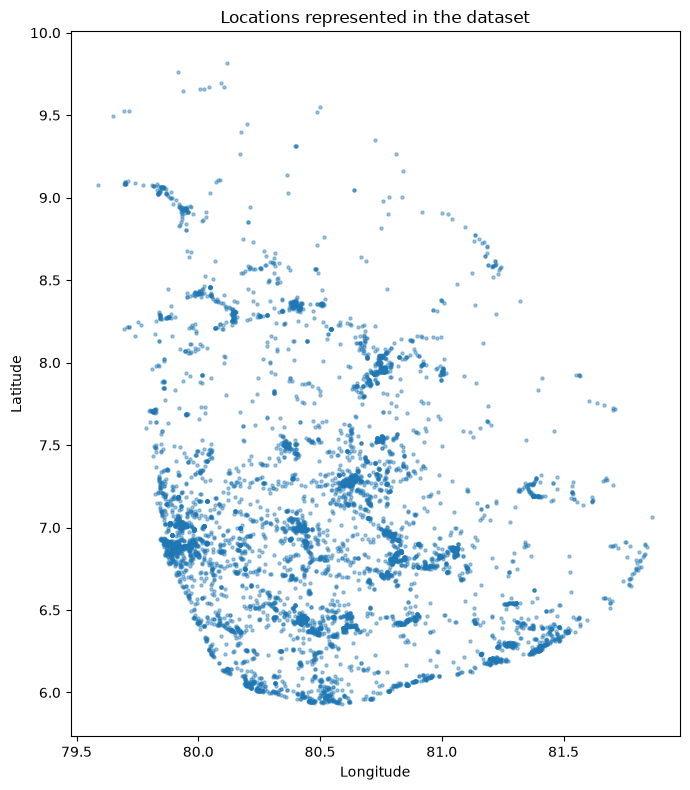

In [11]:
locations.plot.scatter(
    x="longitude",
    y="latitude",
    figsize=(7, 8),
    s=5,
    alpha=0.4
)

plt.title("Locations represented in the dataset")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()

In [12]:
# Create a temporary numeric version for inspection.
numeric_counts = pd.to_numeric(
    df["observation_count"],
    errors="coerce"
)

# Show values that could not be converted to numbers.
non_numeric = df.loc[
    numeric_counts.isna(),
    "observation_count"
]

print("Non-numeric or missing count records:", len(non_numeric))
print("\nValues found:")
print(non_numeric.value_counts(dropna=False))

print("\nNegative counts:", (numeric_counts < 0).sum())
print("Fractional counts:", (numeric_counts.dropna() % 1 != 0).sum())

Non-numeric or missing count records: 12743

Values found:
observation_count
X    12743
Name: count, dtype: int64

Negative counts: 0
Fractional counts: 0


In [13]:
environment_columns = [
    "temperature_min",
    "temperature_mean",
    "temperature_max",
    "precipitation_sum",
    "rain_sum",
    "windspeed_max",
    "windgusts_max",
    "elevation",
    "treecover2000",
    "forest_loss",
    "forest_loss_year"
]

df[environment_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
temperature_min,102929.0,22.342681,2.882730,12.1,20.5,23.1,24.6,28.8
temperature_mean,102929.0,25.010629,2.595128,17.2,24.0,25.8,26.8,31.1
temperature_max,102929.0,28.348813,2.650811,20.0,27.2,28.9,30.0,36.2
precipitation_sum,102929.0,5.409373,9.457497,0.0,0.3,2.1,6.7,177.6
rain_sum,102929.0,5.409373,9.457497,0.0,0.3,2.1,6.7,177.6
windspeed_max,102929.0,12.931531,5.919573,2.3,8.3,11.7,16.6,44.1
windgusts_max,102929.0,32.111147,10.211573,12.2,24.1,29.9,38.5,91.8
elevation,102929.0,307.040047,483.337608,0.0,12.0,27.0,510.0,1281.0
treecover2000,102929.0,61.474988,39.333718,0.0,19.0,82.0,95.0,100.0
forest_loss,102929.0,0.015273,0.122636,0.0,0.0,0.0,0.0,1.0


In [14]:
checks = pd.Series({
    "Minimum temperature above mean": (
        df["temperature_min"] > df["temperature_mean"]
    ).sum(),

    "Mean temperature above maximum": (
        df["temperature_mean"] > df["temperature_max"]
    ).sum(),

    "Negative precipitation": (df["precipitation_sum"] < 0).sum(),

    "Negative rain": (df["rain_sum"] < 0).sum(),

    "Negative wind speed": (df["windspeed_max"] < 0).sum(),

    "Negative wind gust": (df["windgusts_max"] < 0).sum(),

    "Tree cover outside 0–100": (
        ~df["treecover2000"].between(0, 100)
    ).sum(),

    "Forest-loss flag outside 0 or 1": (
        ~df["forest_loss"].isin([0, 1])
    ).sum()
})

checks

Minimum temperature above mean     0
Mean temperature above maximum     0
Negative precipitation             0
Negative rain                      0
Negative wind speed                0
Negative wind gust                 0
Tree cover outside 0–100           0
Forest-loss flag outside 0 or 1    0
dtype: int64

In [15]:
observation_year = dates.dt.year

later_loss = (
    dates.notna()
    & (df["forest_loss_year"] > 0)
    & (df["forest_loss_year"] > observation_year)
)

print("Records with loss after observation:", later_loss.sum())

df.loc[
    later_loss,
    [
        "common_name",
        "latitude",
        "longitude",
        "observation_date",
        "forest_loss",
        "forest_loss_year"
    ]
].head(10)

Records with loss after observation: 47


,common_name,latitude,longitude,observation_date,forest_loss,forest_loss_year
937,Sri Lanka Gray Hornbill,6.782750,80.332685,2010-10-10,1,2019
938,Sri Lanka Hanging-Parrot,6.782750,80.332685,2010-10-10,1,2019
939,White-throated Flowerpecker,6.782750,80.332685,2010-10-10,1,2019
940,Yellow-fronted Barbet,6.782750,80.332685,2010-10-10,1,2019
1626,Black-capped Bulbul,6.423200,80.728900,2011-01-06,1,2023
4383,Sri Lanka Blue-Magpie,6.947509,80.738620,2013-01-06,1,2023
4390,Sri Lanka Wood-Pigeon,6.947509,80.738620,2013-01-06,1,2023
5203,Sri Lanka Green-Pigeon,6.177039,81.207848,2013-04-04,1,2024
6067,Black-capped Bulbul,7.094915,80.161056,2014-01-13,1,2016
6068,Black-capped Bulbul,7.094915,80.161056,2014-01-13,1,2016


In [16]:
# Compare the two columns row by row.
same_values = df["precipitation_sum"].eq(df["rain_sum"])

print("Rows with equal values:", same_values.sum())
print("Rows with different values:", (~same_values).sum())
print("Identical across all rows:", same_values.all())

Rows with equal values: 102929
Rows with different values: 0
Identical across all rows: True


In [17]:
# Inspect location–elevation combinations without repeated observations.
location_elevation = df[
    ["latitude", "longitude", "elevation"]
].drop_duplicates()

print("Distinct elevation values:", df["elevation"].nunique())

print("\nNumber of coordinate pairs associated with each elevation:")
print(
    location_elevation.groupby("elevation")
    .size()
    .sort_index()
)

# Check whether any coordinate pair has multiple elevation values.
values_per_location = df.groupby(
    ["latitude", "longitude"]
)["elevation"].nunique()

print(
    "\nLocations with multiple elevation values:",
    (values_per_location > 1).sum()
)

Distinct elevation values: 18

Number of coordinate pairs associated with each elevation:
elevation
0.0        424
5.0        723
6.0        246
7.0         86
8.0         72
10.0       420
12.0       760
15.0       416
16.0       164
18.0        99
20.0       201
27.0       764
124.0      126
125.0      114
376.0      643
510.0      534
652.0      403
1281.0    1050
dtype: int64

Locations with multiple elevation values: 0


In [18]:
# Compare the stored year/month against the parsed observation date.
year_mismatch = dates.notna() & df["year"].ne(dates.dt.year)
month_mismatch = dates.notna() & df["month"].ne(dates.dt.month)

print("Year mismatches:", year_mismatch.sum())
print("Month mismatches:", month_mismatch.sum())

# Show any records that need investigation.
df.loc[
    year_mismatch | month_mismatch,
    ["observation_date", "year", "month"]
].head(10)

Year mismatches: 0
Month mismatches: 0


,observation_date,year,month


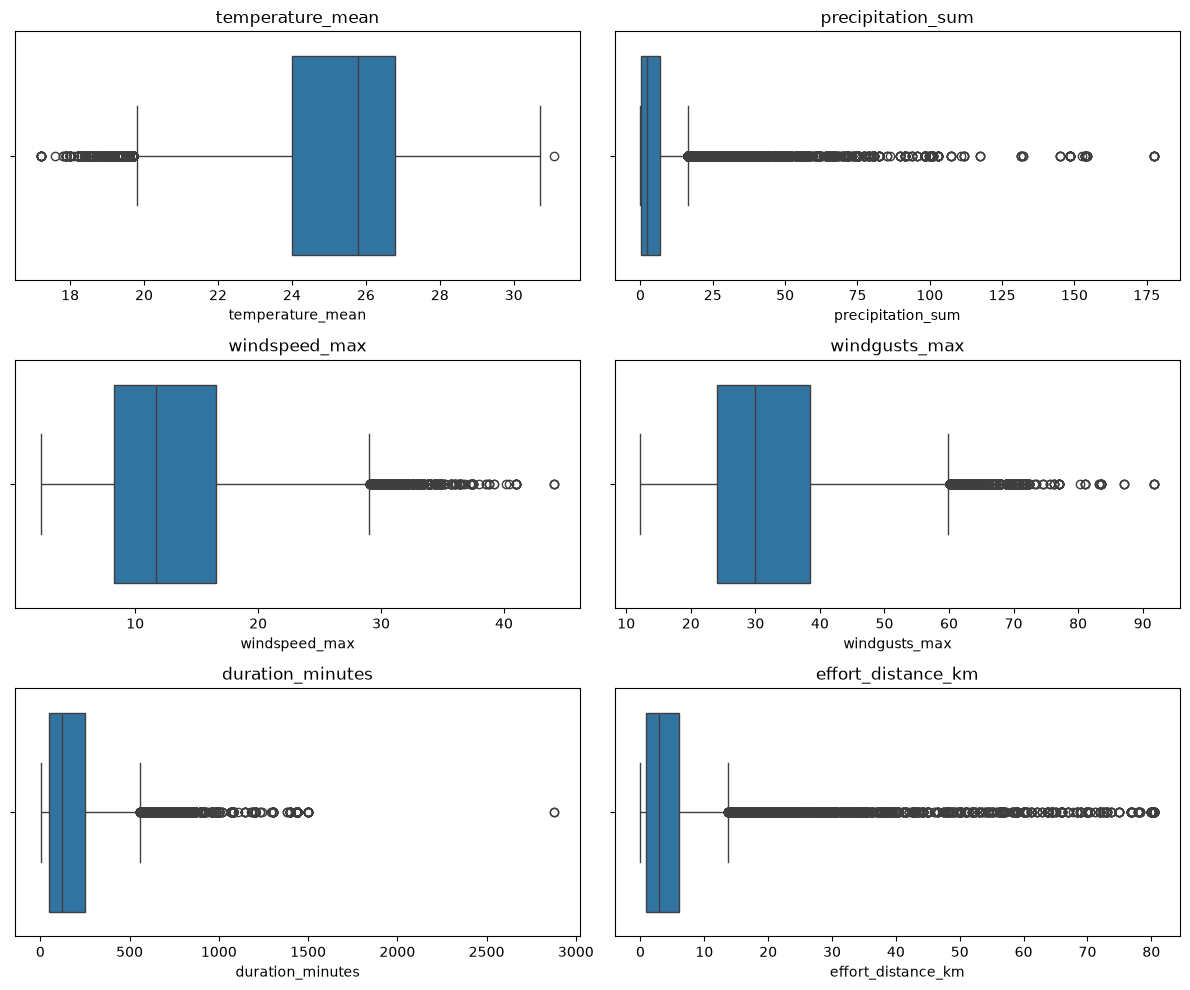

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

columns_to_check = [
    "temperature_mean",
    "precipitation_sum",
    "windspeed_max",
    "windgusts_max",
    "duration_minutes",
    "effort_distance_km"
]

fig, axes = plt.subplots(3, 2, figsize=(12, 10))

for ax, column in zip(axes.flat, columns_to_check):
    sns.boxplot(x=df[column].dropna(), ax=ax)
    ax.set_title(column)

plt.tight_layout()
plt.show()

In [20]:
outlier_summary = []

for column in columns_to_check:
    values = df[column].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    flagged = (values < lower) | (values > upper)

    outlier_summary.append({
        "column": column,
        "lower_limit": lower,
        "upper_limit": upper,
        "flagged_rows": flagged.sum(),
        "flagged_percent": flagged.mean() * 100,
        "minimum": values.min(),
        "maximum": values.max()
    })

pd.DataFrame(outlier_summary).round(2)

,column,lower_limit,upper_limit,flagged_rows,flagged_percent,minimum,maximum
0,temperature_mean,19.80,31.00,4329,4.21,17.2,31.10
1,precipitation_sum,-9.30,16.30,8413,8.17,0.0,177.60
2,windspeed_max,-4.15,29.05,1079,1.05,2.3,44.10
3,windgusts_max,2.50,60.10,1200,1.17,12.2,91.80
4,duration_minutes,-260.00,556.00,7552,8.25,1.0,2880.00
5,effort_distance_km,-6.82,13.70,6310,9.58,0.0,80.47


# HRI workflow: inventory of reusable tables

Run this section to see the inputs for the new HRI preparation workflow. A source being available does not establish its ecological risk interpretation. Old point-weather/elevation columns are retained in raw data only; the merge uses independently sourced grid weather and terrain. Full-period forest loss and pooled bird totals must not become historical predictors.

In [ ]:
from pathlib import Path
import pandas as pd
ROOT = Path.cwd()
while not (ROOT / "configs/study.json").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Run within component4")
    ROOT = ROOT.parent
paths = [ROOT / "data/raw/observations/final_dataset_complete.csv",
         ROOT / "data/metadata/species_traits.csv"]
paths += sorted((ROOT / "data/interim/spatial").glob("*.csv"))
for path in paths:
    sample = pd.read_csv(path, nrows=3)
    print(path.name, "—", len(sample.columns), "columns")
    print(sample.columns.tolist())